In [8]:
import geopandas as gpd

gdf = gpd.read_file("../data/boundaries/geoBoundaries-KGZ-ADM2.geojson")

# print(gdf.columns)
# print(gdf[["shapeName"]])

sokuluk = gdf[
    gdf["shapeName"].str.lower() == "sokuluk"
]

# print(len(sokuluk))

sokuluk.to_file(
    "../data/boundaries/sokuluk_district.geojson",
    driver="GeoJSON"
)

sokuluk_check = gpd.read_file(
    "../data/boundaries/sokuluk_district.geojson"
)

print(sokuluk_check.total_bounds)

[74.1251859  42.43015422 74.559345   43.24065474]


In [11]:
import requests

url = "https://registry.opendata.aws/esa-worldcover/"

response = requests.get(url)

print(response.status_code)
print(response.url)

200
https://registry.opendata.aws/esa-worldcover/


In [15]:
import requests

url = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N42E075_Map.tif"

response = requests.head(url)

print("Status:", response.status_code)
print("Size:", response.headers.get("Content-Length"))

Status: 200
Size: 54019129


In [17]:
import requests

url = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N42E072_Map.tif"

response = requests.head(url)

print("Status:", response.status_code)
print("Size:", response.headers.get("Content-Length"))

Status: 200
Size: 68174596


In [18]:
import rasterio

url = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N42E072_Map.tif"

with rasterio.open(url) as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Resolution:", src.res)

CRS: EPSG:4326
Bounds: BoundingBox(left=72.0, bottom=42.0, right=75.0, top=45.0)
Width: 36000
Height: 36000
Resolution: (8.333333333333333e-05, 8.333333333333333e-05)


In [19]:
import requests

url = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N42E072_Map.tif"

output_path = "../data/raw/worldcover_N42E072.tif"

response = requests.get(url)

with open(output_path, "wb") as f:
    f.write(response.content)

print("Downloaded:", output_path)
print("Size:", len(response.content) / 1024 / 1024, "MB")

Downloaded: ../data/raw/worldcover_N42E072.tif
Size: 65.01636123657227 MB


In [20]:
import rasterio
import numpy as np

path = "../data/raw/worldcover_N42E072.tif"

with rasterio.open(path) as src:
    data = src.read(1)

print("Shape:", data.shape)
print("CRS:", src.crs)
print("Resolution:", src.res)

classes, counts = np.unique(data, return_counts=True)

print("\nClasses:")
for cls, count in zip(classes, counts):
    print(f"Class {cls}: {count:,} pixels")

Shape: (36000, 36000)
CRS: EPSG:4326
Resolution: (8.333333333333333e-05, 8.333333333333333e-05)

Classes:
Class 10: 13,269,114 pixels
Class 20: 63,145,914 pixels
Class 30: 940,939,641 pixels
Class 40: 139,079,325 pixels
Class 50: 9,736,118 pixels
Class 60: 67,952,900 pixels
Class 70: 6,784,636 pixels
Class 80: 5,649,992 pixels
Class 90: 7,411,463 pixels
Class 100: 42,030,897 pixels


In [21]:
import rasterio
from rasterio.mask import mask
import geopandas as gpd

worldcover_path = "../data/raw/worldcover_N42E072.tif"
boundary_path = "../data/boundaries/sokuluk_district.geojson"

sokuluk = gpd.read_file(boundary_path)

with rasterio.open(worldcover_path) as src:
    cropped, transform = mask(
        src,
        sokuluk.geometry,
        crop=True
    )

    print("Original shape:", src.shape)
    print("Cropped shape:", cropped.shape)
    print("CRS:", src.crs)

Original shape: (36000, 36000)
Cropped shape: (1, 9727, 5211)
CRS: EPSG:4326


In [22]:
import numpy as np

cropped_data = cropped[0]

# Count cropland pixels
cropland_pixels = np.sum(cropped_data == 40)

# Count valid pixels
valid_pixels = np.sum(cropped_data != 0)

print("Cropland pixels:", cropland_pixels)
print("Valid pixels:", valid_pixels)

if valid_pixels > 0:
    print(
        "Cropland percentage:",
        round(cropland_pixels / valid_pixels * 100, 2),
        "%"
    )

Cropland pixels: 13616568
Valid pixels: 31940762
Cropland percentage: 42.63 %


In [23]:
from rasterio.transform import array_bounds

output_path = "../data/processed/sokuluk_cropland.tif"

with rasterio.open(worldcover_path) as src:
    cropped, transform = mask(
        src,
        sokuluk.geometry,
        crop=True
    )

    profile = src.profile.copy()

    profile.update({
        "height": cropped.shape[1],
        "width": cropped.shape[2],
        "transform": transform,
        "count": 1,
        "dtype": "uint8",
        "nodata": 0,
        "compress": "lzw"
    })

    # Keep only cropland (class 40)
    cropland = np.where(cropped[0] == 40, 1, 0).astype("uint8")

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(cropland, 1)

print("Saved:", output_path)

Saved: ../data/processed/sokuluk_cropland.tif


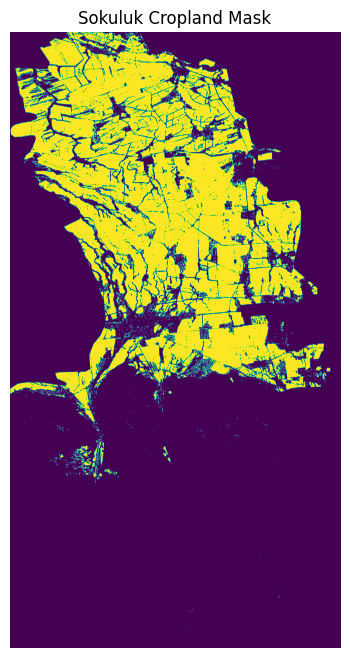

In [24]:
import matplotlib.pyplot as plt
import rasterio

path = "../data/processed/sokuluk_cropland.tif"

with rasterio.open(path) as src:
    cropland = src.read(1)

plt.figure(figsize=(8, 8))
plt.imshow(cropland)
plt.title("Sokuluk Cropland Mask")
plt.axis("off")
plt.show()

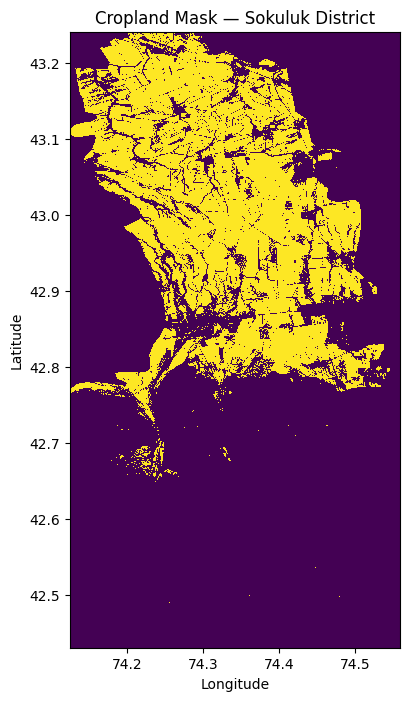

In [3]:
import matplotlib.pyplot as plt
import rasterio

path = "../data/processed/sokuluk_cropland.tif"

with rasterio.open(path) as src:
    cropland = src.read(1)
    bounds = src.bounds

plt.figure(figsize=(10, 8))

plt.imshow(
    cropland,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    interpolation="nearest"
)

plt.title("Cropland Mask — Sokuluk District")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()